# RuBERT: совместное распознавание сущностей и классификация документов

Портфолио-версия учебного NLP-эксперимента. Код использует общий трансформерный энкодер, токенную NER-голову и CLS-голову с attention для отдельных классов. Материалы задания и тексты документов в публичную копию не включены.

## Об эксперименте

На публичном наборе NEREL исследуется совместное обучение NER и multi-label классификации документов. CLS-голова объединяет `[CLS]`, masked mean и представление текста с attention для каждого класса. Предобученный энкодер — `DeepPavlov/rubert-base-cased`.

Данные скачиваются при запуске через `datasets`; в репозитории их нет. Источники: [датасет](https://huggingface.co/datasets/danasone/nerel), [энкодер](https://huggingface.co/DeepPavlov/rubert-base-cased). Условия использования внешних ресурсов определяются их правообладателями.

Сохранённые агрегированные результаты относятся к исходному выполненному эксперименту. Публичная редакция удаляет вывод документов и инструкционные тексты; после её подготовки обучение заново не выполнялось. У изменённых диагностических ячеек outputs очищены. Исходный учебный файл сохранён отдельно.

## Использование ИИ

Проект выполнен в рамках обучения в Яндекс Практикуме. Я запускала эксперименты в Google Colab, отслеживала результаты, сравнивала метрики версий и участвовала в разборе ошибок и оформлении отчёта.

ChatGPT использовался для подготовки и исправления кода, объяснения решений, обсуждения вариантов архитектуры и редактирования текста. Помощь ИИ включала программную реализацию. Представленные метрики получены при реальном выполнении исходного эксперимента.

## Содержание

1. Окружение и параметры.
2. Агрегированный обзор данных.
3. Разделение, токенизация и загрузчики.
4. Общий энкодер и две выходные головы.
5. Обучение, валидация и сохранение checkpoint.
6. Метрики, графики и диагностика.
7. Сравнение FP32 и динамической INT8-квантизации.

## Подготовка окружения

In [1]:
%pip install -q "torch>=2.1" "transformers>=4.40,<5" "datasets>=2.18" "scikit-learn>=1.3" "matplotlib>=3.7" "pandas>=2" "tqdm>=4.66" "safetensors>=0.4"
import os, random, json, copy, time, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from datasets import load_dataset

SEED=42
MODEL_NAME='DeepPavlov/rubert-base-cased'  # более мощный энкодер; требует больше GPU-памяти
MAX_LENGTH=512
BATCH_SIZE=8
EPOCHS=24
LR=2e-5
WEIGHT_DECAY=0.01
PATIENCE=6
USE_UNCERTAINTY=True
NUM_WORKERS=0
OUT=Path('nerel_attention_outputs'); OUT.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE,'torch:',torch.__version__)
if DEVICE.type=='cpu': print('ВНИМАНИЕ: обучение на CPU может занимать значительно больше времени.')
HEAD_LR=1e-4
THRESHOLD_GRID=np.round(np.arange(0.20,0.651,0.025),3)

## Данные: агрегированный обзор

Рассчитываются длины документов, число сущностей и частоты CLS-меток. Исходные тексты и отдельные записи не выводятся.

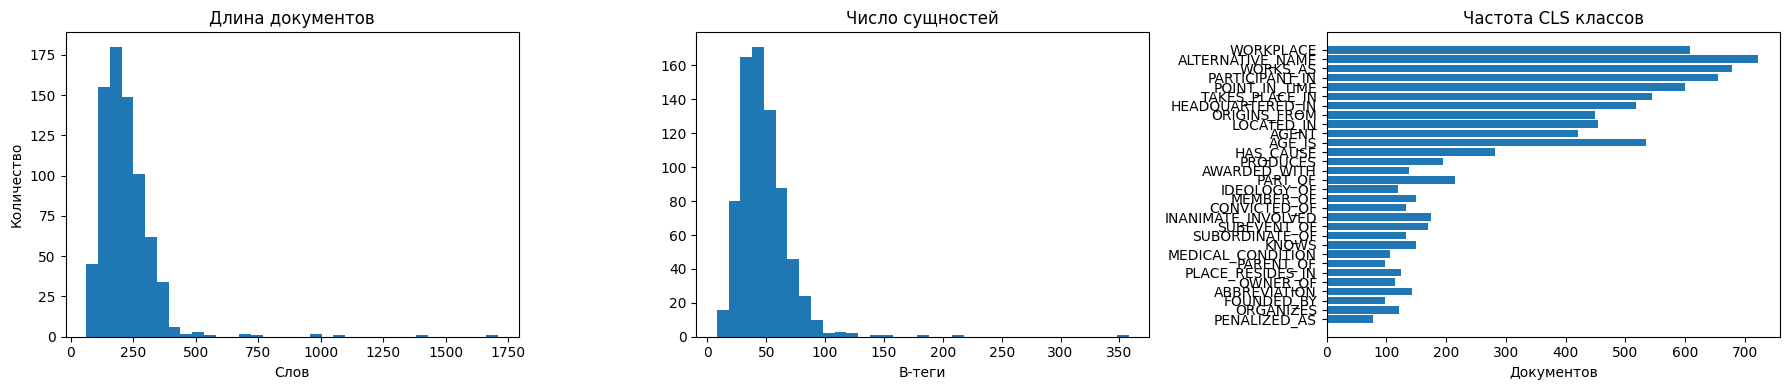

             Класс  Позитивных документов     Доля
         WORKPLACE                    609 0.816354
  ALTERNATIVE_NAME                    723 0.969169
          WORKS_AS                    678 0.908847
    PARTICIPANT_IN                    656 0.879357
     POINT_IN_TIME                    600 0.804290
    TAKES_PLACE_IN                    545 0.730563
  HEADQUARTERED_IN                    518 0.694370
      ORIGINS_FROM                    449 0.601877
        LOCATED_IN                    454 0.608579
             AGENT                    421 0.564343
            AGE_IS                    535 0.717158
         HAS_CAUSE                    282 0.378016
          PRODUCES                    195 0.261394
      AWARDED_WITH                    137 0.183646
           PART_OF                    214 0.286863
       IDEOLOGY_OF                    119 0.159517
         MEMBER_OF                    150 0.201072
      CONVICTED_OF                    133 0.178284
INANIMATE_INVOLVED             

In [ ]:
raw=load_dataset('danasone/nerel')['train']
print(raw, raw.features)
assert all(k in raw.column_names for k in ('text','tokens','token_spans','tags','cls_vec'))
assert len(raw)>100
CLS_NAMES=['WORKPLACE','ALTERNATIVE_NAME','WORKS_AS','PARTICIPANT_IN','POINT_IN_TIME','TAKES_PLACE_IN','HEADQUARTERED_IN','ORIGINS_FROM','LOCATED_IN','AGENT','AGE_IS','HAS_CAUSE','PRODUCES','AWARDED_WITH','PART_OF','IDEOLOGY_OF','MEMBER_OF','CONVICTED_OF','INANIMATE_INVOLVED','SUBEVENT_OF','SUBORDINATE_OF','KNOWS','MEDICAL_CONDITION','PARENT_OF','PLACE_RESIDES_IN','OWNER_OF','ABBREVIATION','FOUNDED_BY','ORGANIZES','PENALIZED_AS']
assert len(CLS_NAMES)==30
all_tags=sorted(set(t for row in raw for t in row['tags'])-{'O'})
NER_LABELS=['O']+all_tags; label2id={v:i for i,v in enumerate(NER_LABELS)};id2label={i:v for v,i in label2id.items()}
print('Число BIO-меток:',len(NER_LABELS),'Типов сущностей:',len(set(t[2:] for t in all_tags)))
invalid=[]
for i,row in enumerate(raw):
    if not(len(row['tokens'])==len(row['tags'])==len(row['token_spans'])) or len(row['cls_vec'])!=30 or not set(row['cls_vec'])<= {0,1}:
        invalid.append(i)
print('Некорректных записей:',len(invalid)); assert not invalid, 'Проверьте исходный формат данных'
lengths=np.array([len(r['tokens']) for r in raw]); nentities=np.array([sum(t.startswith('B-') for t in r['tags']) for r in raw]);freq=np.asarray([r['cls_vec'] for r in raw]).sum(axis=0)
fig,ax=plt.subplots(1,3,figsize=(18,4))
ax[0].hist(lengths,bins=35);ax[0].set(title='Длина документов',xlabel='Слов',ylabel='Количество')
ax[1].hist(nentities,bins=35);ax[1].set(title='Число сущностей',xlabel='B-теги')
ax[2].barh(CLS_NAMES, freq);ax[2].invert_yaxis();ax[2].set(title='Частота CLS классов',xlabel='Документов')
plt.tight_layout();plt.show()
print(pd.DataFrame({'Класс':CLS_NAMES,'Позитивных документов':freq,'Доля':freq/len(raw)}).to_string(index=False))
print('Медиана слов:',np.median(lengths),'доля документов >512 слов:',round(float((lengths>512).mean()),3),'пустые CLS:',sum(freq==0))

### Наблюдения
В исходном наборе 746 документов. В предыдущем EDA наблюдались 29 типов сущностей; частоты CLS сильно различались: `ALTERNATIVE_NAME` — 723 документа, `PENALIZED_AS` — 78. Медиана длины — 201,5 слова. Эти значения пересчитываются выше. Реальное усечение по subword-токенам измеряется ниже; число слов не равно числу токенов RuBERT.

## Токенизация и DataLoader

Символьные границы исходных токенов сопоставляются с offsets токенизатора. Метка присваивается первому subword, остальные позиции исключаются из loss и метрик с помощью `-100`. Padding выполняется до длины самого длинного примера в батче.

### Разделение данных

In [3]:
indices=np.arange(len(raw))
train_idx, tmp_idx=train_test_split(indices,test_size=0.2,random_state=SEED,shuffle=True)
val_idx,test_idx=train_test_split(tmp_idx,test_size=0.5,random_state=SEED,shuffle=True)
assert not(set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))
print({'train':len(train_idx),'val':len(val_idx),'test':len(test_idx)})
train_rows=[raw[int(i)] for i in train_idx];val_rows=[raw[int(i)] for i in val_idx];test_rows=[raw[int(i)] for i in test_idx]

{'train': 596, 'val': 75, 'test': 75}


In [ ]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME,use_fast=True)
assert tokenizer.is_fast

def tokenize_and_align_labels(row,max_length=MAX_LENGTH):
    # Оригинальный текст + символьные позиции: мы не заменяем пунктуацию/пробелы новым текстом.
    enc=tokenizer(row['text'],truncation=True,max_length=max_length,return_offsets_mapping=True)
    offsets=enc.pop('offset_mapping');spans=row['token_spans']; tags=row['tags']
    labs=[-100]*len(offsets); seen=set();j=0
    for k,(start,end) in enumerate(offsets):
        if start==end:continue   # специальные токены
        while j<len(spans) and spans[j][1]<=start:j+=1
        if j>=len(spans):continue
        left,right=spans[j]
        # Только первый subword, полностью или частично попадающий в размеченное слово.
        if left<=start<right and j not in seen:
            labs[k]=label2id[tags[j]]; seen.add(j)
    enc['labels']=labs;enc['cls_labels']=[float(x) for x in row['cls_vec']]
    return enc

class NERELDataset(Dataset):
    def __init__(self,rows):self.data=[tokenize_and_align_labels(r) for r in tqdm(rows,desc='Tokenizing')]
    def __len__(self):return len(self.data)
    def __getitem__(self,i):return self.data[i]

def collate(batch):
    padded=tokenizer.pad([{k:v for k,v in x.items() if k not in ('labels','cls_labels')} for x in batch],padding=True,return_tensors='pt')
    length=padded['input_ids'].shape[1]
    padded['labels']=torch.tensor([x['labels']+[-100]*(length-len(x['labels'])) for x in batch],dtype=torch.long)
    padded['cls_labels']=torch.tensor([x['cls_labels'] for x in batch],dtype=torch.float)
    return padded

train_ds=NERELDataset(train_rows);val_ds=NERELDataset(val_rows);test_ds=NERELDataset(test_rows)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,collate_fn=collate,num_workers=NUM_WORKERS)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate,num_workers=NUM_WORKERS)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate,num_workers=NUM_WORKERS)
ex=train_ds[0];assert len(ex['labels'])==len(ex['input_ids']);assert len(ex['cls_labels'])==30
assert all((v==-100 or 0<=v<len(NER_LABELS)) for v in ex['labels'])
assert any(v!=-100 for v in ex['labels']);assert all(v==-100 for v in ex['labels'][:1])
b=next(iter(train_loader));assert b['input_ids'].shape==b['labels'].shape and b['cls_labels'].shape[1]==30
print('Sanity checks OK.')
# Реальная длина в subword-токенах, а не число исходных слов.
subword_lengths = np.array([len(tokenizer(r['text'], truncation=False)['input_ids']) for r in raw])
print(f'Усечено при MAX_LENGTH={MAX_LENGTH}: {(subword_lengths > MAX_LENGTH).mean():.1%}')
plt.hist(subword_lengths, bins=35)
plt.axvline(MAX_LENGTH, color='red', label='MAX_LENGTH')
plt.xlabel('Subword-токенов со специальными токенами'); plt.ylabel('Документов')
plt.legend(); plt.show()
# Контроль первого subword и границ разметки на нескольких документах.
for row in train_rows[:20]:
    spans = row['token_spans']
    assert all(0 <= left < right <= len(row['text']) for left, right in spans)
    assert all(spans[k][1] <= spans[k+1][0] for k in range(len(spans)-1))
    enc = tokenize_and_align_labels(row)
    offsets = tokenizer(row['text'], truncation=True, max_length=MAX_LENGTH,
                        return_offsets_mapping=True)['offset_mapping']
    observed = []
    for (start, end), label in zip(offsets, enc['labels']):
        if label == -100: continue
        matches = [j for j, (left, right) in enumerate(spans) if left <= start < right]
        assert len(matches) == 1
        j = matches[0]
        assert label == label2id[row['tags'][j]] and j not in observed
        observed.append(j)
print('Проверки выравнивания пройдены.')

В используемой версии NEREL уже представлены токены, их символьные границы, BIO-метки и векторы cls_vec. Поэтому повторное построение разметки из исходных аннотаций не выполняется. В ноутбуке проверяются согласованность полей, допустимость меток и корректность их переноса на subword-токены.

## 4. Общая модель и label attention

NER-голова — линейный классификатор на первом subword каждого исходного слова. Остальные позиции игнорируются с `-100`. Метрика NER — macro-F1 BIO-меток без `O`, включая ошибки предсказания сущностей на истинных `O`-позициях.

CLS-голова содержит два пути. Первый использует `[CLS]` и средний вектор содержательных токенов. Во втором у каждой характеристики есть обучаемый query; скалярные произведения query с эмбеддингами токенов превращаются softmax в веса. По этим весам получается отдельное представление для каждого класса. Сумма логитов двух путей поступает в BCEWithLogitsLoss. Padding, CLS и SEP исключены из attention и усреднения.

Attention-веса — диагностический сигнал, не доказательство причин решения модели. Loss первого и единственного этапа обучения использует uncertainty weighting для NER и CLS. Энкодер обучается с LR 2e-5, новые головы — с LR 1e-4.

In [5]:
class LabelAttentionHead(nn.Module):
    def __init__(self, hidden_size, num_classes):
        super().__init__()
        self.norm=nn.LayerNorm(hidden_size)
        self.dropout=nn.Dropout(0.2)
        self.queries=nn.Parameter(torch.empty(num_classes,hidden_size))
        self.label_weights=nn.Parameter(torch.empty(num_classes,hidden_size))
        self.label_bias=nn.Parameter(torch.zeros(num_classes))
        nn.init.normal_(self.queries,std=0.02)
        nn.init.normal_(self.label_weights,std=0.02)
        self.global_head=nn.Sequential(
            nn.Linear(2*hidden_size,hidden_size//2),nn.GELU(),nn.Dropout(0.2),
            nn.Linear(hidden_size//2,num_classes))

    def forward(self,hidden,content_mask,return_attention=False):
        # Вырожденный пустой текст: используем CLS, чтобы softmax не дал NaN.
        content_mask=content_mask.clone().bool()
        empty=~content_mask.any(dim=1)
        content_mask[empty,0]=True
        normalized=self.norm(hidden)
        scores=torch.einsum('blh,ch->bcl',normalized,self.queries)/(hidden.shape[-1]**0.5)
        scores=scores.masked_fill(~content_mask[:,None,:],torch.finfo(scores.dtype).min)
        attention=torch.softmax(scores,dim=-1)
        attended=torch.einsum('bcl,blh->bch',attention,normalized)
        local_logits=(self.dropout(attended)*self.label_weights[None,:,:]).sum(-1)+self.label_bias
        weights=content_mask.unsqueeze(-1).to(normalized.dtype)
        mean=(normalized*weights).sum(1)/weights.sum(1).clamp_min(1.)
        global_logits=self.global_head(self.dropout(torch.cat([normalized[:,0],mean],dim=-1)))
        logits=global_logits+local_logits
        return (logits,attention) if return_attention else logits

class JointModel(nn.Module):
    def __init__(self,model_name,num_ner_labels,use_uncertainty_weight=True,ner_class_weights=None):
        super().__init__()
        self.encoder=AutoModel.from_pretrained(model_name)
        hidden=self.encoder.config.hidden_size
        self.dropout=nn.Dropout(0.1)
        self.token_head=nn.Linear(hidden,num_ner_labels)
        self.cls_head=LabelAttentionHead(hidden,len(CLS_NAMES))
        self.use_uncertainty_weight=use_uncertainty_weight
        self.log_sigma_token=nn.Parameter(torch.tensor(0.))
        self.log_sigma_cls=nn.Parameter(torch.tensor(0.))
        self.token_loss_fn=nn.CrossEntropyLoss(weight=ner_class_weights,ignore_index=-100)
        self.cls_loss_fn=nn.BCEWithLogitsLoss()

    def forward(self,input_ids,attention_mask,labels=None,cls_labels=None,token_type_ids=None,
                return_attention=False):
        kwargs=dict(input_ids=input_ids,attention_mask=attention_mask)
        if token_type_ids is not None:kwargs['token_type_ids']=token_type_ids
        hidden=self.encoder(**kwargs).last_hidden_state
        token_logits=self.token_head(self.dropout(hidden))
        content_mask=attention_mask.bool() & (input_ids!=tokenizer.cls_token_id) & (input_ids!=tokenizer.sep_token_id)
        cls_output=self.cls_head(hidden,content_mask,return_attention=return_attention)
        cls_logits,attention=cls_output if return_attention else (cls_output,None)
        result=dict(token_logits=token_logits,cls_logits=cls_logits)
        if return_attention:result['attention']=attention
        if labels is not None and cls_labels is not None:
            token_loss=self.token_loss_fn(token_logits.reshape(-1,token_logits.shape[-1]),labels.reshape(-1))
            cls_loss=self.cls_loss_fn(cls_logits,cls_labels)
            if self.use_uncertainty_weight:
                loss=(torch.exp(-2*self.log_sigma_token)*token_loss+self.log_sigma_token+
                      torch.exp(-2*self.log_sigma_cls)*cls_loss+self.log_sigma_cls)
            else:loss=token_loss+cls_loss
            result.update(loss=loss,token_loss=token_loss,cls_loss=cls_loss)
        return result

train_tag_counts=np.bincount([label for item in train_ds for label in item['labels'] if label!=-100],minlength=len(NER_LABELS))
weights=np.clip((train_tag_counts.sum()/np.maximum(train_tag_counts,1))**.35,1.,12.)
weights[0]=1.
class_weights=torch.tensor(weights,dtype=torch.float32,device=DEVICE)
model=JointModel(MODEL_NAME,len(NER_LABELS),USE_UNCERTAINTY,class_weights).to(DEVICE)
model.eval()
with torch.no_grad():
    sample={k:v.to(DEVICE) for k,v in b.items()}
    out=model(**sample,return_attention=True)
assert out['token_logits'].shape[:2]==sample['labels'].shape
assert out['cls_logits'].shape==sample['cls_labels'].shape
assert torch.isfinite(out['loss'])
assert torch.allclose(out['attention'].sum(-1),torch.ones_like(out['attention'].sum(-1)),atol=1e-5)
# Проверяем отсутствие влияния padding на attention.
padding=(sample['attention_mask']==0)[:,None,:].expand_as(out['attention'])
assert (out['attention'][padding]==0).all()
print('Проверки forward, loss, attention и padding пройдены.')

Some weights of the model checkpoint at DeepPavlov/rubert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Проверки forward, loss, attention и padding пройдены.


## 5. Обучение и выбор checkpoint

Лимит — 24 эпохи, patience — 6. Выбираю наибольший validation CLS micro-F1 среди checkpoint с validation NER ≥ 0,50. Для каждого checkpoint единый CLS-порог ищется на заранее заданной сетке. До первого допустимого checkpoint сохраняется временная модель по среднему двух метрик; если NER так и не достигнет 0,50 на validation, это явно выводится. Test открывается только после выбора.

Validation F1 после подбора эпохи и порога оптимистичен. Это не отдельная независимая оценка качества.

In [6]:
def collect_metrics(token_true,token_pred,cls_true,cls_probs,threshold=0.5):
    # Все BIO-типы, кроме O. Учитываем только позиции labels != -100.
    token_f1=f1_score(token_true,token_pred,labels=list(range(1,len(NER_LABELS))),average='macro',zero_division=0)
    cls_f1=f1_score(cls_true,(np.asarray(cls_probs)>=threshold).astype(int),average='micro',zero_division=0)
    return {'token_f1':float(token_f1),'cls_f1':float(cls_f1)}

def run_epoch(model,loader,optimizer=None,scheduler=None,return_raw=False):
    training=optimizer is not None
    model.train(training)
    totals=Counter();n=0; yt=[];yp=[];ct=[];cp=[]
    for batch in tqdm(loader,leave=False,desc='train' if training else 'eval'):
        batch={k:v.to(DEVICE) for k,v in batch.items()}
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            output=model(**batch)
            if training:
                output['loss'].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
                if scheduler is not None:scheduler.step()
        bs=batch['input_ids'].size(0);n+=bs
        for key in ['loss','token_loss','cls_loss']:totals[key]+=output[key].detach().item()*bs
        mask=(batch['labels']!=-100)
        yt.extend(batch['labels'][mask].detach().cpu().tolist())
        yp.extend(output['token_logits'].argmax(-1)[mask].detach().cpu().tolist())
        ct.extend(batch['cls_labels'].detach().cpu().numpy().astype(int).tolist())
        cp.extend(torch.sigmoid(output['cls_logits']).detach().cpu().numpy().tolist())
    result={k:totals[k]/n for k in ['loss','token_loss','cls_loss']}
    result.update(collect_metrics(yt,yp,ct,cp))
    if return_raw:return result,{'ner_true':yt,'ner_pred':yp,'cls_true':np.asarray(ct),'cls_probs':np.asarray(cp)}
    return result


def choose_threshold(y,probs):
    scores=[f1_score(y,probs>=t,average='micro',zero_division=0) for t in THRESHOLD_GRID]
    i=int(np.argmax(scores))
    return float(THRESHOLD_GRID[i]),float(scores[i])

optimizer=torch.optim.AdamW([
    {'params':model.encoder.parameters(),'lr':LR},
    {'params':list(model.token_head.parameters())+list(model.cls_head.parameters()),'lr':HEAD_LR},
    {'params':[model.log_sigma_token,model.log_sigma_cls],'lr':LR,'weight_decay':0.},
],weight_decay=WEIGHT_DECAY)
steps=EPOCHS*len(train_loader)
scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,int(.1*steps)),num_training_steps=steps)
history=[];best_score=-float('inf');best_epoch=0;best_eligible=False;bad_epochs=0;best_threshold=.5
for epoch in range(1,EPOCHS+1):
    start=time.time()
    tr=run_epoch(model,train_loader,optimizer,scheduler)
    va,vr=run_epoch(model,val_loader,return_raw=True)
    threshold,cls_f1=choose_threshold(vr['cls_true'],vr['cls_probs'])
    eligible=va['token_f1']>=.5
    score=cls_f1 if eligible else (va['token_f1']+cls_f1)/2
    improved=(eligible and not best_eligible) or (eligible==best_eligible and score>best_score+1e-4)
    row=dict(epoch=epoch,seconds=round(time.time()-start,1),val_cls_tuned_f1=cls_f1,
             threshold=threshold,eligible=eligible,
             ner_loss_weight=float(torch.exp(-2*model.log_sigma_token).detach()),
             cls_loss_weight=float(torch.exp(-2*model.log_sigma_cls).detach()))
    row.update({'train_'+k:v for k,v in tr.items()});row.update({'val_'+k:v for k,v in va.items()})
    history.append(row);print(pd.DataFrame([row]).round(4).to_string(index=False))
    if improved:
        best_score=score;best_epoch=epoch;best_eligible=eligible;best_threshold=threshold;bad_epochs=0
        torch.save(model.state_dict(),OUT/'best_model.pt')
    else:bad_epochs+=1
    if bad_epochs>=PATIENCE:
        print('Early stopping');break
hist=pd.DataFrame(history);hist.to_csv(OUT/'epoch_metrics.csv',index=False)
model.load_state_dict(torch.load(OUT/'best_model.pt',map_location=DEVICE,weights_only=True));model.eval()
CLS_THRESHOLDS=np.full(len(CLS_NAMES),best_threshold)
print('Выбрана эпоха:',best_epoch,'порог:',best_threshold,'допустимый NER:',best_eligible)
if not best_eligible:print('Ни один checkpoint не достиг validation NER >= 0.50.')

 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
     1     12.7            0.7398       0.45     False           0.9994           0.9997      4.1521            3.5581          0.5946          0.0092         0.611    3.2345           2.757        0.4789         0.038      0.7321


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
     2     12.1            0.7604      0.375     False           0.9979           1.0001      2.3407            1.8549          0.4874          0.2311        0.7173     1.488          1.0419        0.4472        0.3767      0.7397


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
     3     12.2            0.7676       0.45      True           0.9971           1.0036      1.2093            0.7727          0.4375          0.5276        0.7427    1.0085          0.5954        0.4136        0.5955      0.7632


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
     4     12.1            0.7822       0.35      True           0.9972           1.0078      0.8644            0.4631          0.4017          0.6772        0.7674    0.8966          0.5054        0.3921        0.6712      0.7718


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
     5     12.1            0.7884      0.375      True           0.9978           1.0121      0.6974            0.3233          0.3749          0.7577        0.7808    0.8764          0.4936        0.3841        0.6823      0.7606


...

 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
    20     12.1            0.8219        0.5      True           1.0167           1.0486      0.1398            0.0375          0.1272          0.9635          0.95    0.9943          0.6213        0.3764        0.7288      0.8219


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
    21     12.3            0.8285      0.475      True           1.0172           1.0493      0.1316            0.0367          0.1207          0.9648        0.9536    0.9983          0.6263        0.3754        0.7298       0.827


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
    22     12.2            0.8281      0.475      True           1.0176           1.0498      0.1246            0.0362          0.1148          0.9631        0.9592    0.9972          0.6202        0.3802        0.7325      0.8257


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
    23     12.2            0.8266       0.45      True           1.0178           1.0501      0.1169            0.0348          0.1091          0.9656        0.9627    0.9984          0.6219        0.3797        0.7326      0.8233


 epoch  seconds  val_cls_tuned_f1  threshold  eligible  ner_loss_weight  cls_loss_weight  train_loss  train_token_loss  train_cls_loss  train_token_f1  train_cls_f1  val_loss  val_token_loss  val_cls_loss  val_token_f1  val_cls_f1
    24     12.1            0.8259      0.475      True           1.0179           1.0502      0.1129             0.034          0.1063          0.9647        0.9651    1.0045          0.6257        0.3818        0.7316       0.824
Выбрана эпоха: 21 порог: 0.475 допустимый NER: True


## 6. Графики и разрыв train/validation

,epoch,seconds,val_cls_tuned_f1,threshold,eligible,ner_loss_weight,cls_loss_weight,train_loss,train_token_loss,train_cls_loss,train_token_f1,train_cls_f1,val_loss,val_token_loss,val_cls_loss,val_token_f1,val_cls_f1
0,1,12.7,0.7398,0.450,False,0.9994,0.9997,4.1521,3.5581,0.5946,0.0092,0.6110,3.2345,2.7570,0.4789,0.0380,0.7321
1,2,12.1,0.7604,0.375,False,0.9979,1.0001,2.3407,1.8549,0.4874,0.2311,0.7173,1.4880,1.0419,0.4472,0.3767,0.7397
2,3,12.2,0.7676,0.450,True,0.9971,1.0036,1.2093,0.7727,0.4375,0.5276,0.7427,1.0085,0.5954,0.4136,0.5955,0.7632
3,4,12.1,0.7822,0.350,True,0.9972,1.0078,0.8644,0.4631,0.4017,0.6772,0.7674,0.8966,0.5054,0.3921,0.6712,0.7718
4,5,12.1,0.7884,0.375,True,0.9978,1.0121,0.6974,0.3233,0.3749,0.7577,0.7808,0.8764,0.4936,0.3841,0.6823,0.7606
5,6,12.1,0.7953,0.450,True,0.9988,1.0161,0.5878,0.2381,0.3513,0.8083,0.7971,0.8562,0.4880,0.3702,0.7063,0.7882
6,7,12.1,0.8000,0.325,True,1.0000,1.0199,0.5120,0.1876,0.3273,0.8504,0.8110,0.8511,0.4949,0.3589,0.7109,0.7899
7,8,12.2,0.8101,0.425,True,1.0015,1.0235,0.4510,0.1474,0.3079,0.8838,0.8290,0.8565,0.5088,0.3511,0.7090,0.8021
8,9,12.1,0.8103,0.300,True,1.0030,1.0268,0.3999,0.1204,0.2856,0.8976,0.8401,0.8467,0.4987,0.3518,0.7200,0.8010
9,10,12.3,0.8113,0.525,True,1.0047,1.0300,0.3556,0.0979,0.2656,0.9106,0.8564,0.8619,0.5200,0.3462,0.7216,0.8074


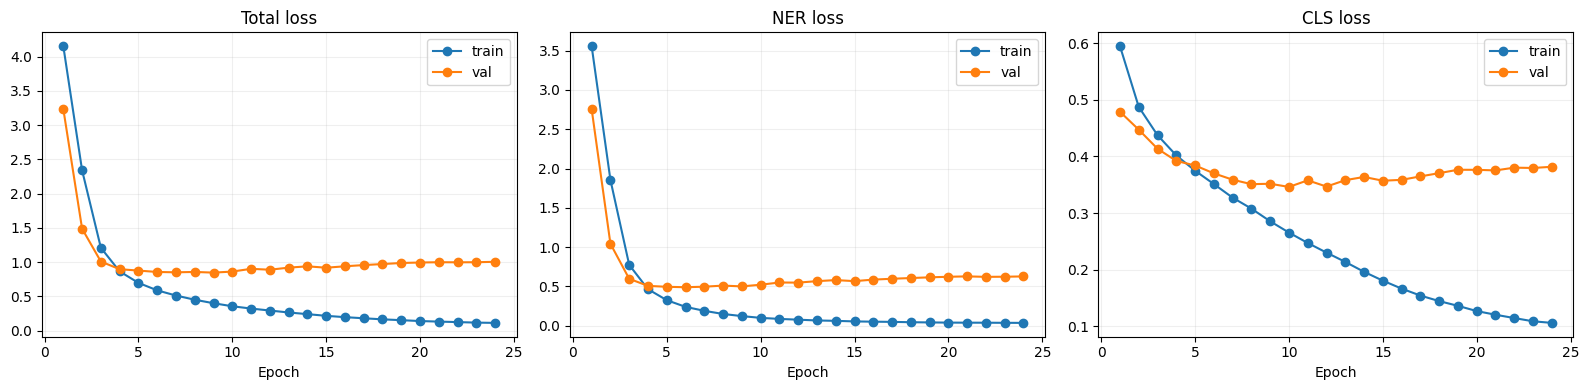

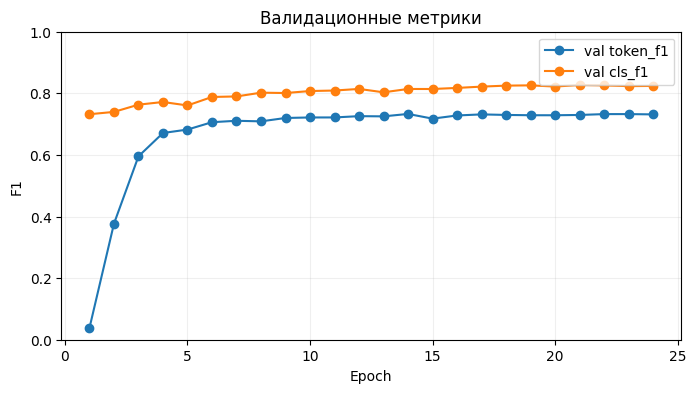

Эпоха лучшей модели: 21
token_loss: train=0.0367; val=0.6263; gap=+0.5896
cls_loss: train=0.1207; val=0.3754; gap=+0.2547


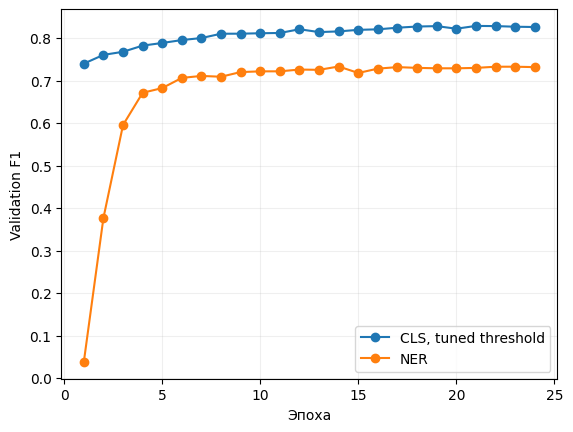

In [7]:
display(hist.round(4))
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,metric,title in zip(axes,['loss','token_loss','cls_loss'],['Total loss','NER loss','CLS loss']):
    ax.plot(hist.epoch,hist['train_'+metric],marker='o',label='train')
    ax.plot(hist.epoch,hist['val_'+metric],marker='o',label='val')
    ax.set(title=title,xlabel='Epoch');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for metric in ['token_f1','cls_f1']:ax.plot(hist.epoch,hist['val_'+metric],marker='o',label='val '+metric)
ax.set(xlabel='Epoch',ylabel='F1',ylim=(0,1),title='Валидационные метрики');ax.legend();ax.grid(alpha=.2);plt.show()
print('Эпоха лучшей модели:',best_epoch)
for task in ['token_loss','cls_loss']:
    row=hist.loc[hist.epoch==best_epoch].iloc[0]
    print(f'{task}: train={row["train_"+task]:.4f}; val={row["val_"+task]:.4f}; gap={row["val_"+task]-row["train_"+task]:+.4f}')
plt.plot(hist.epoch,hist.val_cls_tuned_f1,marker='o',label='CLS, tuned threshold')
plt.plot(hist.epoch,hist.val_token_f1,marker='o',label='NER')
plt.xlabel('Эпоха');plt.ylabel('Validation F1');plt.legend();plt.grid(alpha=.2);plt.show()

### Вывод по обучению

Обучение завершилось после 24 эпох. По выбранному правилу лучшей стала модель на 21-й эпохе: CLS micro-F1 на валидации после настройки порога составил 0,8285.

К концу обучения заметен разрыв между обучающей и валидационной выборками. На выбранной эпохе NER loss составил 0,0367 на обучении и 0,6263 на валидации, а CLS loss — 0,1207 и 0,3754 соответственно. Это указывает на переобучение: модель всё лучше запоминает обучающие данные, но качество на новых примерах растёт значительно медленнее. Поэтому для итоговой оценки используются веса выбранной эпохи, а не последней.

## 7. Итоговая оценка и частотный baseline

Частотный baseline использует только распространённость меток train. Его порог подбирается на validation. Сравнение показывает пользу текстовых признаков, но не доказывает преимущества multi-task над single-task.

In [8]:
val_m,val_raw=run_epoch(model,val_loader,return_raw=True)
selected_val_cls=float(f1_score(val_raw['cls_true'],val_raw['cls_probs']>=CLS_THRESHOLDS,average='micro',zero_division=0))
train_priors=np.asarray([r['cls_vec'] for r in train_rows],dtype=float).mean(0)
prior_threshold,prior_val_f1=choose_threshold(val_raw['cls_true'],np.broadcast_to(train_priors,val_raw['cls_true'].shape))
test_m,test_raw=run_epoch(model,test_loader,return_raw=True)
selected_test_probs=test_raw['cls_probs']
final=collect_metrics(test_raw['ner_true'],test_raw['ner_pred'],test_raw['cls_true'],selected_test_probs,CLS_THRESHOLDS)
prior_test_f1=float(f1_score(test_raw['cls_true'],np.broadcast_to(train_priors>=prior_threshold,test_raw['cls_true'].shape),average='micro',zero_division=0))
display(pd.DataFrame([
    dict(model='Частоты train',val_cls=prior_val_f1,test_cls=prior_test_f1),
    dict(model='RuBERT + label attention',val_cls=selected_val_cls,test_cls=final['cls_f1'])]).round(4))
print('Test NER macro-F1:',final['token_f1'],'| CLS micro-F1:',final['cls_f1'])
print(classification_report(test_raw['ner_true'],test_raw['ner_pred'],labels=list(range(1,len(NER_LABELS))),target_names=NER_LABELS[1:],zero_division=0))
from sklearn.metrics import precision_recall_fscore_support
cls_pred=(selected_test_probs>=CLS_THRESHOLDS).astype(int)
precision,recall,cls_f1,_=precision_recall_fscore_support(test_raw['cls_true'],cls_pred,average=None,zero_division=0)
cls_report=pd.DataFrame(dict(class_name=CLS_NAMES,precision=precision,recall=recall,f1=cls_f1,support=test_raw['cls_true'].sum(0)))
display(cls_report);cls_report.to_csv(OUT/'cls_report.csv',index=False)

,model,val_cls,test_cls
0,Частоты train,0.7375,0.7226
1,RuBERT + label attention,0.8285,0.8009


Test NER macro-F1: 0.7674633294666657 | CLS micro-F1: 0.8009313154831199
                     precision    recall  f1-score   support

              B-AGE       0.98      0.99      0.98        91
            B-AWARD       0.72      0.87      0.79        68
             B-CITY       0.88      0.91      0.90       100
          B-COUNTRY       0.94      0.90      0.92       187
            B-CRIME       0.81      0.76      0.78        33
             B-DATE       0.90      0.92      0.91       396
          B-DISEASE       0.69      0.69      0.69        49
         B-DISTRICT       0.75      0.86      0.80         7
            B-EVENT       0.63      0.77      0.70       377
         B-FACILITY       0.73      0.75      0.74        36
           B-FAMILY       0.00      0.00      0.00         0
         B-IDEOLOGY       0.88      0.68      0.76        31
         B-LANGUAGE       1.00      1.00      1.00         6
              B-LAW       0.84      0.81      0.83        32
         B-

,class_name,precision,recall,f1,support
0,WORKPLACE,0.906250,0.935484,0.920635,62
1,ALTERNATIVE_NAME,0.986667,1.000000,0.993289,74
2,WORKS_AS,0.958904,1.000000,0.979021,70
3,PARTICIPANT_IN,0.833333,0.967742,0.895522,62
4,POINT_IN_TIME,0.794118,0.947368,0.864000,57
5,TAKES_PLACE_IN,0.800000,0.888889,0.842105,54
6,HEADQUARTERED_IN,0.826923,0.826923,0.826923,52
7,ORIGINS_FROM,0.818182,0.818182,0.818182,44
8,LOCATED_IN,0.795455,0.760870,0.777778,46
9,AGENT,0.725000,0.743590,0.734177,39


## 8. Инференс и качественный анализ

Показываю метку первого subword каждого исходного слова, как при обучении. BIO на продолжениях subword не интерпретируется. Слова разделяются пробелами; пунктуация может остаться частью слова, что соответствует формату исходных tokens.

In [ ]:
def predict_text(text, threshold=None):
    if threshold is None: threshold = CLS_THRESHOLDS
    model.eval()
    # Та же единица разметки, что в наборе: слово между пробелами.
    # Не назначаем метки продолжениям subword, исключённым из обучения.
    import re
    words = [(m.start(), m.end()) for m in re.finditer(r'\S+', text)]
    enc = tokenizer(text, return_offsets_mapping=True, truncation=True,
                    max_length=MAX_LENGTH, return_tensors='pt')
    offsets = enc.pop('offset_mapping')[0].tolist()
    with torch.no_grad():
        out = model(**{k:v.to(DEVICE) for k,v in enc.items()})
    probs = torch.sigmoid(out['cls_logits'])[0].cpu().numpy()
    pred = out['token_logits'][0].argmax(-1).cpu().tolist()
    ner = []; seen = set(); j = 0
    for (start, end), tag in zip(offsets, pred):
        if start == end: continue
        while j < len(words) and words[j][1] <= start: j += 1
        if j < len(words) and words[j][0] <= start < words[j][1] and j not in seen:
            left, right = words[j]; seen.add(j)
            ner.append((text[left:right], id2label[tag], left, right))
    thresholds = np.asarray(threshold, dtype=float)
    if thresholds.ndim == 0: thresholds = np.full(len(CLS_NAMES), float(thresholds))
    if thresholds.shape != (len(CLS_NAMES),): raise ValueError('Неверная форма порогов')
    cls = sorted([(name,float(p)) for name,p,t in zip(CLS_NAMES,probs,thresholds) if p>=t],
                 key=lambda item:-item[1])
    return ner, cls

text = 'Марина Соколова представила проект компании Вектор в Казани 12 апреля 2025 года.'
ner, cls = predict_text(text)
print('CLS predictions:', cls)
print('NER по первому subword каждого исходного слова:')
for word, tag, _, _ in ner: print(f'{word:20s} {tag}')
print('Пунктуация остаётся частью исходного слова, если между ними нет пробела.')

In [ ]:
@torch.no_grad()
def cls_probabilities(batch):
    model.eval()
    inputs={k:v.to(DEVICE) for k,v in batch.items() if k in ('input_ids','attention_mask','token_type_ids')}
    return torch.sigmoid(model(**inputs)['cls_logits']).cpu().numpy()

# Диагностика без публикации документов, исходных токенов или их разметки.
model.eval()
confusions=Counter();fp_counts=np.zeros(len(CLS_NAMES),dtype=int);fn_counts=fp_counts.copy()
for batch in test_loader:
    batch={k:v.to(DEVICE) for k,v in batch.items()}
    with torch.no_grad():predictions=model(**batch)
    gold=batch['labels'];pred=predictions['token_logits'].argmax(-1)
    mask=(gold!=-100)&(gold!=pred)
    for actual,guessed in zip(gold[mask].cpu().tolist(),pred[mask].cpu().tolist()):
        confusions[(id2label[actual],id2label[guessed])]+=1
    truth=batch['cls_labels'].cpu().numpy().astype(int)
    binary=(torch.sigmoid(predictions['cls_logits']).cpu().numpy()>=CLS_THRESHOLDS).astype(int)
    fp_counts+=((binary==1)&(truth==0)).sum(0)
    fn_counts+=((binary==0)&(truth==1)).sum(0)
display(pd.DataFrame([dict(gold_label=a,predicted_label=b,count=count)
                     for (a,b),count in confusions.most_common(15)]))
display(pd.DataFrame(dict(class_name=CLS_NAMES,false_positive=fp_counts,false_negative=fn_counts)))

### Интерпретация ошибок

В исходном эксперименте встречались ошибки границ сущностей и путаница между организациями, событиями и произведениями искусства. Для CLS сложнее оказались некоторые менее частые характеристики. Агрегированные F1 для `FOUNDED_BY` и `OWNER_OF` составили 0,25 и около 0,333. У этих классов низкая полнота.

Публичная диагностика выводит только суммарные ошибки типов NER и количества FP/FN по CLS-классам. Тексты и разметка отдельных документов не публикуются. Общий micro-F1 не отражает качество каждого класса в отдельности.

### Диагностика attention

Вместо токенов отдельных документов выводятся средняя энтропия attention и максимальный вес по каждому классу. Эти величины характеризуют концентрацию весов; они не доказывают правильность или причинность решения.

In [ ]:
attention_entropy=[];attention_max=[]
model.eval()
for batch in val_loader:
    batch={k:v.to(DEVICE) for k,v in batch.items()}
    with torch.no_grad():result=model(**batch,return_attention=True)
    att=result['attention'].clamp_min(1e-12)
    attention_entropy.append((-(att*att.log()).sum(-1)).cpu().numpy())
    attention_max.append(result['attention'].max(-1).values.cpu().numpy())
display(pd.DataFrame(dict(class_name=CLS_NAMES,
    mean_attention_entropy=np.concatenate(attention_entropy).mean(0),
    mean_max_attention=np.concatenate(attention_max).mean(0))))

## Результаты и сохранение

В исходном запуске получены token-level NER macro-F1 без O = 0,7675 и CLS micro-F1 = 0,8009. Сохраняются веса, токенизатор, конфигурация и агрегированные метрики.

In [12]:
print(f'Лучший checkpoint: эпоха {best_epoch}; единый порог {best_threshold:.3f}')
print(f'Test NER={final["token_f1"]:.4f}; CLS={final["cls_f1"]:.4f}')
print(f'Разница CLS с частотным baseline: {final["cls_f1"]-prior_test_f1:+.4f}')
print('Сравнение с историческим v4 (исследовательское):',f'{final["cls_f1"]-.7939:+.4f}')
config=dict(model_name=MODEL_NAME,architecture='LabelAttentionHead+CLS+mean',seed=SEED,
    max_length=MAX_LENGTH,batch_size=BATCH_SIZE,epochs=EPOCHS,lr=LR,head_lr=HEAD_LR,
    use_uncertainty=USE_UNCERTAINTY,label2id=label2id,cls_names=CLS_NAMES,
    best_epoch=best_epoch,cls_thresholds=CLS_THRESHOLDS.tolist(),
    train_indices=train_idx.tolist(),val_indices=val_idx.tolist(),test_indices=test_idx.tolist())
(OUT/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf8')
(OUT/'results.json').write_text(json.dumps(dict(validation=val_m,validation_cls_tuned=selected_val_cls,
    test=final,frequency_baseline_test=prior_test_f1),ensure_ascii=False,indent=2),encoding='utf8')
tokenizer.save_pretrained(OUT/'tokenizer')
print('Ограничения: небольшие данные, выбор по validation и неоднократный просмотр test в истории проекта.')
print('Артефакты:',sorted(str(p) for p in OUT.iterdir()))

Лучший checkpoint: эпоха 21; единый порог 0.475
Test NER=0.7675; CLS=0.8009
Разница CLS с частотным baseline: +0.0784
Сравнение с историческим v4 (исследовательское): +0.0070
Ограничения: небольшие данные, выбор по validation и неоднократный просмотр test в истории проекта.
Артефакты: ['nerel_attention_outputs/best_model.pt', 'nerel_attention_outputs/cls_report.csv', 'nerel_attention_outputs/config.json', 'nerel_attention_outputs/epoch_metrics.csv', 'nerel_attention_outputs/results.json', 'nerel_attention_outputs/tokenizer']


### Проверка квантизации

Квантизация позволяет хранить часть весов модели в менее точном формате. Это может уменьшить размер модели и ускорить её работу, но иногда приводит к снижению качества.

В этом блоке сравниваются исходная модель FP32 и версия с динамической INT8-квантизацией линейных слоёв. Обе модели проверяются на одном CPU с одинаковыми порогами классификации. Сравниваются качество NER и CLS, время обработки текста и размер файла весов.

Качество оценивается на всей тестовой выборке. Скорость измеряется на восьми документах после предварительных запусков; время токенизации в измерение не входит.



In [14]:
RUN_QUANTIZATION=True
if RUN_QUANTIZATION:
    import gc, io, statistics
    # Не создаём CPU-копию при уже почти заполненной RAM.
    available_bytes=None
    try:
        import psutil
        available_bytes=psutil.virtual_memory().available
    except ImportError:
        pass
    if available_bytes is not None and available_bytes < 6*1024**3:
        print('Квантизация пропущена: свободно менее 6 GiB системной ОЗУ. Основная оценка сохранена.')
    else:
        previous_threads=torch.get_num_threads()
        original_device=next(model.parameters()).device
        cpu_fp32=None;cpu_int8=None
        try:
            torch.set_num_threads(min(4,os.cpu_count() or 1))
            # Освобождаем состояния Adam после завершённого обучения.
            optimizer.state.clear()
            optimizer.zero_grad(set_to_none=True)
            gc.collect()
            # Временно переносим основную модель на CPU, затем копируем только CPU-тензоры.
            model.to('cpu').eval()
            if torch.cuda.is_available():torch.cuda.empty_cache()
            cpu_fp32=copy.deepcopy(model).eval()
            model.to(original_device)

            @torch.inference_mode()
            def evaluate_cpu(net):
                yt=[];yp=[];ct=[];cp=[]
                for batch in tqdm(test_loader,desc='CPU quality',leave=False):
                    mask=batch['labels']!=-100
                    inputs={k:value.cpu() for k,value in batch.items()
                            if k in ('input_ids','attention_mask','token_type_ids')}
                    output=net(**inputs)
                    yt.extend(batch['labels'][mask].tolist())
                    yp.extend(output['token_logits'].argmax(-1)[mask].tolist())
                    ct.extend(batch['cls_labels'].numpy().astype(int))
                    cp.extend(torch.sigmoid(output['cls_logits']).numpy())
                return collect_metrics(yt,yp,np.asarray(ct),np.asarray(cp),CLS_THRESHOLDS)

            benchmark_batches=[]
            for j in range(min(8,len(test_ds))):
                batch=collate([test_ds[j]])
                benchmark_batches.append({k:value.cpu() for k,value in batch.items()
                    if k in ('input_ids','attention_mask','token_type_ids')})

            @torch.inference_mode()
            def median_latency(net):
                for batch in benchmark_batches[:2]:net(**batch)
                timings=[]
                for _ in range(3):
                    start=time.perf_counter()
                    for batch in benchmark_batches:net(**batch)
                    timings.append((time.perf_counter()-start)/len(benchmark_batches))
                return statistics.median(timings)*1000

            # Размер через файл, чтобы не хранить ещё один большой байтовый буфер в RAM.
            fp_path=OUT/'quantization_fp32_state.pt'
            torch.save(cpu_fp32.state_dict(),fp_path)
            fp_size=fp_path.stat().st_size/(1024**2)
            fp_metrics=evaluate_cpu(cpu_fp32)
            fp_latency=median_latency(cpu_fp32)
            # inplace=True: выделенная CPU-копия преобразуется без ещё одного deepcopy.
            cpu_int8=torch.ao.quantization.quantize_dynamic(
                cpu_fp32,{nn.Linear},dtype=torch.qint8,inplace=True).eval()
            cpu_fp32=None
            int_path=OUT/'quantization_int8_state.pt'
            torch.save(cpu_int8.state_dict(),int_path)
            int_size=int_path.stat().st_size/(1024**2)
            int_metrics=evaluate_cpu(cpu_int8)
            int_latency=median_latency(cpu_int8)
            quant_report=pd.DataFrame([
                dict(precision='FP32 CPU',ner_f1=fp_metrics['token_f1'],cls_f1=fp_metrics['cls_f1'],
                     ms_per_document=fp_latency,state_size_MiB=fp_size),
                dict(precision='INT8 CPU',ner_f1=int_metrics['token_f1'],cls_f1=int_metrics['cls_f1'],
                     ms_per_document=int_latency,state_size_MiB=int_size)])
            display(quant_report.round(4))
            quant_report.to_csv(OUT/'quantization_report.csv',index=False)
            print(f'Отношение времени FP32/INT8: {fp_latency/int_latency:.3f}')
            print(f'Изменение NER F1: {int_metrics["token_f1"]-fp_metrics["token_f1"]:+.4f}')
            print(f'Изменение CLS F1: {int_metrics["cls_f1"]-fp_metrics["cls_f1"]:+.4f}')
            print('Ускорение наблюдается.' if int_latency<fp_latency else 'Ускорения на этом CPU не наблюдается.')
        finally:
            model.to(original_device).eval()
            del cpu_fp32,cpu_int8
            torch.set_num_threads(previous_threads)
            gc.collect()
else:
    print('Квантизация пока отключена. Обучение и основная оценка выполняются как в v5.')


/tmp/ipykernel_8471/2130762643.py:66: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  cpu_int8=torch.ao.quantization.quantize_dynamic(


,precision,ner_f1,cls_f1,ms_per_document,state_size_MiB
0,FP32 CPU,0.7675,0.8009,155.3199,681.1885
1,INT8 CPU,0.7325,0.7937,86.9188,434.7126


Отношение времени FP32/INT8: 1.787
Изменение NER F1: -0.0349
Изменение CLS F1: -0.0073
Ускорение наблюдается.


### Компромисс скорости и качества

На использованном CPU динамическая квантизация линейных слоёв сократила среднее время на документ со 155,32 до 86,92 мс (отношение времени около 1,79). Размер сериализованных весов уменьшился с 681,19 до 434,71 МиБ. Измерение времени выполнено на восьми документах после прогрева, медиана трёх повторов; токенизация не включена.

NER macro-F1 изменился с 0,7675 до 0,7325, CLS micro-F1 — с 0,8009 до 0,7937. В качестве основной версии сохранена FP32 с более высоким качеством. Ускорение относится к указанной среде и протоколу; переносить его на любое оборудование нельзя.

## Итоги и ограничения

Общий RuBERT-энкодер решает две задачи с отдельными выходными головами. CLS использует глобальные признаки и attention для каждого класса. В исходном эксперименте выбран checkpoint 21-й эпохи и CLS-порог 0,475. Результаты: NER macro-F1 0,7675, CLS micro-F1 0,8009. Частотный CLS baseline дал 0,7226.

Есть разрыв train/validation loss и признаки переобучения. Датасет небольшой, метки несбалансированы, 3,4% документов обрезаются при лимите 512 subword-токенов. Токенный NER F1 не равен F1 целых сущностей. Test просматривался в нескольких итерациях разработки, поэтому это исследовательские результаты; для независимого подтверждения нужен новый набор. Преимущество multi-task над single-task отдельно не установлено.

INT8 уменьшает размер и время CPU-инференса при снижении качества. Основные агрегированные результаты сохранены из исходного запуска; изменённые публичные диагностические ячейки требуют выполнения. Данные, тексты задания и комментарии ревьюера в публичную версию не включены.